# House Sale Price Prediction — Ames Housing

**Context**: As a data scientist at a real estate agency, I need to develop a model capable of estimating a house's sale price based on its characteristics.

**\*\***_\*My Official Submission for the Kaggle Competition\*_**\*\***

**Plan**
1. Data exploration
2. Data analysis and preprocessing
3. Model training (Linear Regression, Random Forest, Gradient Boosting)
4. Evaluation (MAE, RMSE, R²)
5. Bonus: `GridSearchCV`, feature importance, 

**Dataset**: *Ames Housing* (Dean De Cock) approximately 2,900 house sales in Ames, Iowa, with 80 features and the target variable `SalePrice`.

You can access the dataset via the following link : https://www.kaggle.com/datasets/shashanknecrothapa/ames-housing-dataset 

In [65]:
import os, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [67]:
random_state = 42 #we fix a random state to reproduce the same results each time we execute the code

In [68]:
from sklearn.model_selection import train_test_split, cross_val_score, KFold, GridSearchCV
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

In [69]:
warnings.filterwarnings("ignore") # to delete warning messages
sns.set_theme(style="whitegrid", palette="deep") # we select a theme for seaborn package
plt.rcParams["figure.dpi"] = 100 

## Step 1 — Data Exploration

### 1.1 Loading CSV file

In [71]:
df = pd.read_csv("AmesHousing.csv")

df.head()

,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


In [72]:
# we drop the following columns because they aren't useful to predict
df = df.drop(columns=["Order", "PID"])
df.columns = df.columns.str.replace(' ', '')

#
target = "SalePrice"

print(f"Shape : {df.shape[0]} rows x {df.shape[1]} columns")
df.head()

Shape : 2930 rows x 80 columns


,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,AllPub,Corner,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,Corner,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,AllPub,Corner,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,AllPub,Inside,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


### 1.2 Columns and data types

In [73]:
print("Distribution of types :")
print(df.dtypes.value_counts())

Distribution of types :
object     43
int64      26
float64    11
Name: count, dtype: int64


In [74]:
num_cols_all = df.select_dtypes(include="number").columns.tolist() #we get a list with all number columns 
cat_cols_all = df.select_dtypes(exclude="number").columns.tolist() #we get a list with all non-number columns 
print(f"{len(num_cols_all)} numerical variables, {len(cat_cols_all)} categorical variables \n")
print("Numerical  :", num_cols_all)
print("\n Categorical :", cat_cols_all)

37 numerical variables, 43 categorical variables 

Numerical  : ['MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemod/Add', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold', 'SalePrice']

 Categorical : ['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'Kit

In [75]:
df[num_cols_all].describe().T.round(1) 

,count,mean,std,min,25%,50%,75%,max
MSSubClass,2930.0,57.4,42.6,20.0,20.0,50.0,70.0,190.0
LotFrontage,2440.0,69.2,23.4,21.0,58.0,68.0,80.0,313.0
LotArea,2930.0,10147.9,7880.0,1300.0,7440.2,9436.5,11555.2,215245.0
OverallQual,2930.0,6.1,1.4,1.0,5.0,6.0,7.0,10.0
OverallCond,2930.0,5.6,1.1,1.0,5.0,5.0,6.0,9.0
YearBuilt,2930.0,1971.4,30.2,1872.0,1954.0,1973.0,2001.0,2010.0
YearRemod/Add,2930.0,1984.3,20.9,1950.0,1965.0,1993.0,2004.0,2010.0
MasVnrArea,2907.0,101.9,179.1,0.0,0.0,0.0,164.0,1600.0
BsmtFinSF1,2929.0,442.6,455.6,0.0,0.0,370.0,734.0,5644.0
BsmtFinSF2,2929.0,49.7,169.2,0.0,0.0,0.0,0.0,1526.0


### 1.3 Missing values and duplicated 

In [76]:
missing = df.isna().sum()
print(missing)

MSSubClass         0
MSZoning           0
LotFrontage      490
LotArea            0
Street             0
                ... 
MoSold             0
YrSold             0
SaleType           0
SaleCondition      0
SalePrice          0
Length: 80, dtype: int64


In [77]:
missing = missing[missing > 0].sort_values(ascending=False)
print(missing)
miss_df = pd.DataFrame({"missing": missing, "percentage": (missing / len(df) * 100).round(2)})
print(f"{len(miss_df)} columns with missing values")
display(miss_df.head(20))

PoolQC          2917
MiscFeature     2824
Alley           2732
Fence           2358
MasVnrType      1775
FireplaceQu     1422
LotFrontage      490
GarageQual       159
GarageCond       159
GarageYrBlt      159
GarageFinish     159
GarageType       157
BsmtExposure      83
BsmtFinType2      81
BsmtCond          80
BsmtQual          80
BsmtFinType1      80
MasVnrArea        23
BsmtFullBath       2
BsmtHalfBath       2
BsmtFinSF1         1
BsmtFinSF2         1
Electrical         1
TotalBsmtSF        1
BsmtUnfSF          1
GarageArea         1
GarageCars         1
dtype: int64
27 columns with missing values


,missing,percentage
PoolQC,2917,99.56
MiscFeature,2824,96.38
Alley,2732,93.24
Fence,2358,80.48
MasVnrType,1775,60.58
FireplaceQu,1422,48.53
LotFrontage,490,16.72
GarageQual,159,5.43
GarageCond,159,5.43
GarageYrBlt,159,5.43


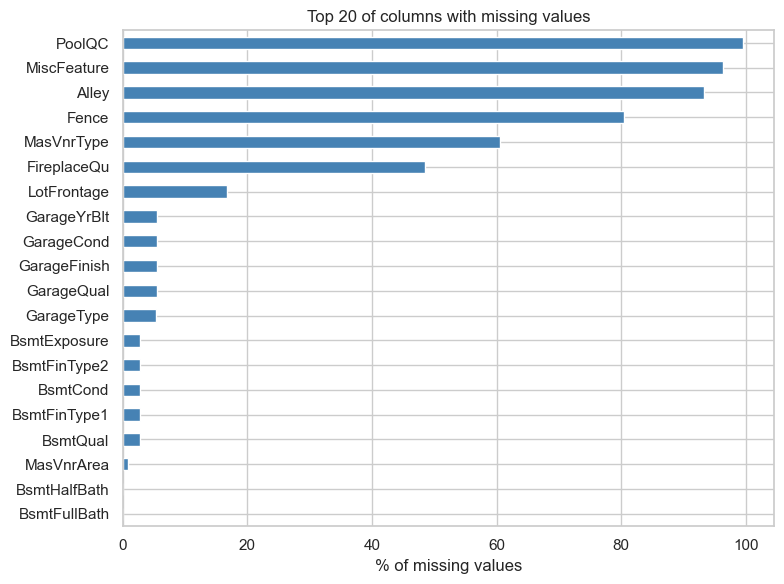

In [ ]:
fig, ax = plt.subplots(figsize=(8, 6))
miss_df["percentage"].head(20).sort_values().plot.barh(ax=ax, color="steelblue")
ax.set_xlabel("% of missing values")
ax.set_title("Top 20 of columns with missing values")
plt.tight_layout()
plt.show()

In the Ames Housing dataset, many NaN values do **not** represent missing data but rather indicate the **absence** of a feature or facility
(`PoolQC` = no pool, `Alley` = no alley, `BsmtQual` = no basement, `GarageType` = no garage, etc.).
We will therefore treat them as a separate category (`"None"`) rather than removing them.

In [80]:
n_dup = df.duplicated().sum()
print(f"Duplicated rows : {n_dup}")

Duplicated rows : 0


### 1.4 Sale price distribution

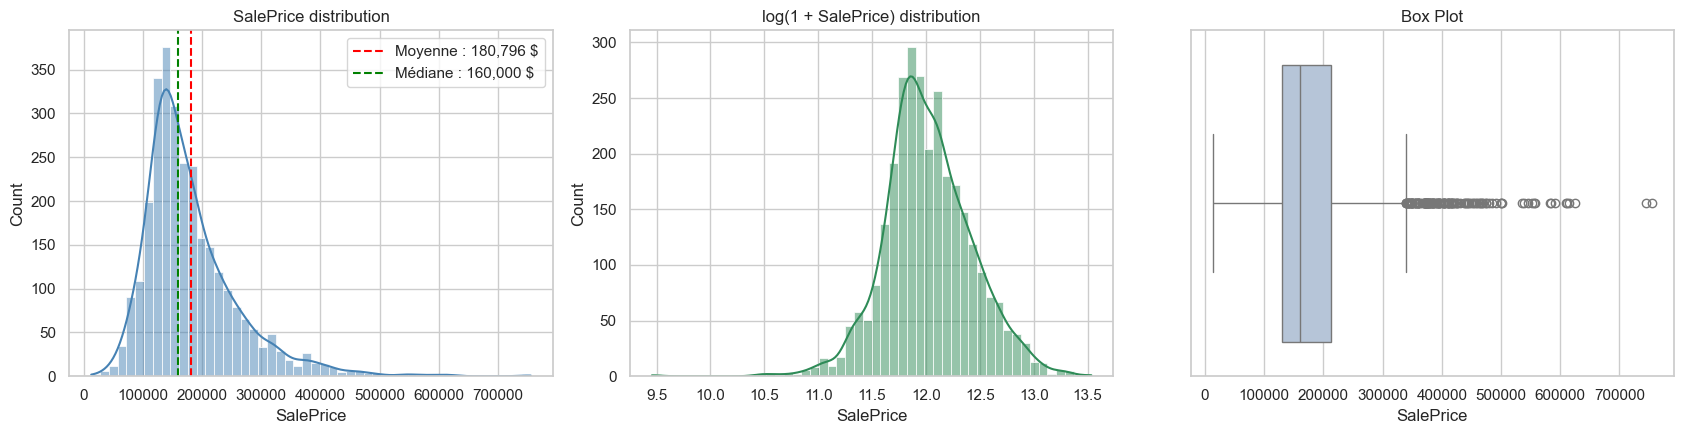

count      2930.0
mean     180796.0
std       79887.0
min       12789.0
25%      129500.0
50%      160000.0
75%      213500.0
max      755000.0
Name: SalePrice, dtype: float64

Raw Skewness : 1.74
Skewness after log        : -0.01


In [81]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

sns.histplot(df[cible], bins=50, kde=True, ax=axes[0], color="steelblue")
axes[0].axvline(df[cible].mean(), color="red", ls="--", label=f"Moyenne : {df[cible].mean():,.0f} $")
axes[0].axvline(df[cible].median(), color="green", ls="--", label=f"Médiane : {df[cible].median():,.0f} $")
axes[0].set_title("SalePrice distribution")
axes[0].legend()

sns.histplot(np.log1p(df[cible]), bins=50, kde=True, ax=axes[1], color="seagreen")
axes[1].set_title("log(1 + SalePrice) distribution")

sns.boxplot(x=df[cible], ax=axes[2], color="lightsteelblue")
axes[2].set_title("Box Plot")
plt.tight_layout(); plt.show()

print(df[cible].describe().round(0))
print(f"\nRaw Skewness : {df[cible].skew():.2f}")
print(f"Skewness after log        : {np.log1p(df[cible]).skew():.2f}")

**Key finding**: The distribution is right-skewed, with a few very expensive houses. Applying a logarithmic transformation makes it approximately symmetrical.

We will train the models on **log(1 + price)**: this helps stabilize the learning process and makes the model focus more on **percentage errors** rather than absolute errors in dollars.

However, the evaluation metrics will still be calculated in dollars, after applying the inverse transformation.

## Step 2 — Analyze and preparation

### 2.1 Relationship Between Sale Price and Living Area

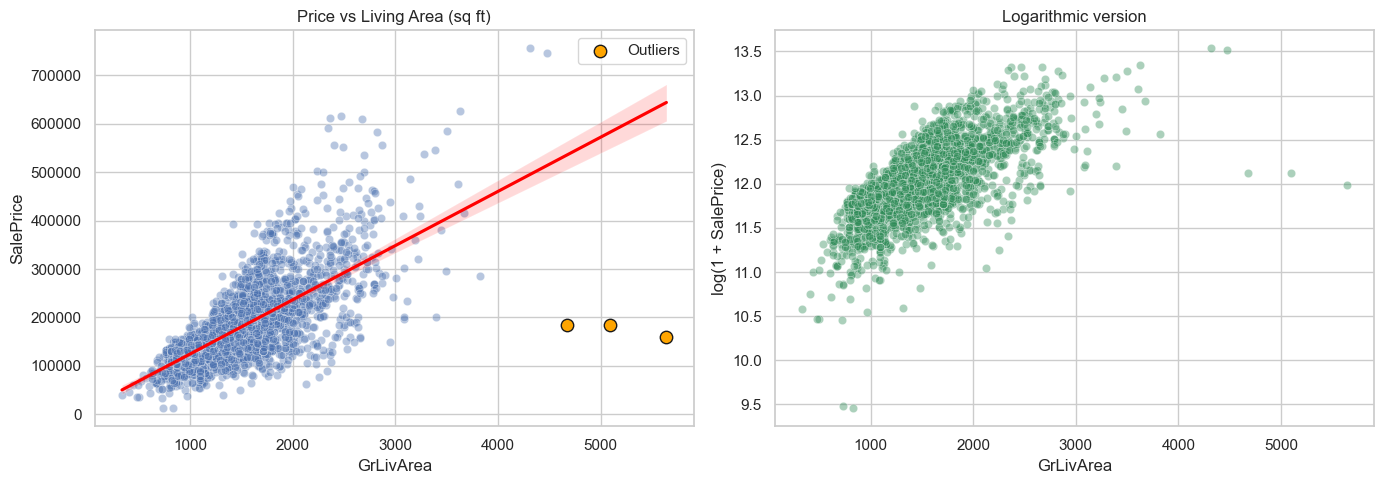

Pearson's correlation price / area : 0.707
Spearman's correlation : 0.723

3 outliers (big houses sold at low price) :


,GrLivArea,OverallQual,Neighborhood,SalePrice
1498,5642,10,Edwards,160000
2180,5095,10,Edwards,183850
2181,4676,10,Edwards,184750


In [84]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(data=df, x="GrLivArea", y=cible, alpha=0.4, ax=axes[0])
sns.regplot(data=df, x="GrLivArea", y=cible, scatter=False, color="red", ax=axes[0])
axes[0].set_title("Price vs Living Area (sq ft)")

# Mise en évidence des valeurs aberrantes classiques du dataset
outliers = (df["GrLivArea"] > 4000) & (df[cible] < 300000)
axes[0].scatter(df.loc[outliers, "GrLivArea"], df.loc[outliers, cible],
                color="orange", s=80, edgecolor="k", label="Outliers")
axes[0].legend()

sns.scatterplot(data=df, x="GrLivArea", y=np.log1p(df[cible]), alpha=0.4, ax=axes[1], color="seagreen")
axes[1].set_ylabel("log(1 + SalePrice)")
axes[1].set_title("Logarithmic version")
plt.tight_layout()
plt.show()

print(f"Pearson's correlation price / area : {df['GrLivArea'].corr(df[cible]):.3f}")
print(f"Spearman's correlation : {df['GrLivArea'].corr(df[cible], method='spearman'):.3f}")
print(f"\n{outliers.sum()} outliers (big houses sold at low price) :")
display(df.loc[outliers, ["GrLivArea", "OverallQual", "Neighborhood", cible]])

The living area is strongly correlated with the sale price. The few orange points (> 4,000 sq ft for less than $300,000) represent atypical sales (the dataset's author himself recommends removing them): they would pull the regression line downward. We therefore remove these outliers.

In [87]:
df = df[~outliers].reset_index(drop=True) # We use ~ to keep all non-outliers. 
print(f"Dimensions after removing outliers : {df.shape}")

Dimensions after removing outliers : (2921, 80)


### 2.2 Feature Selection

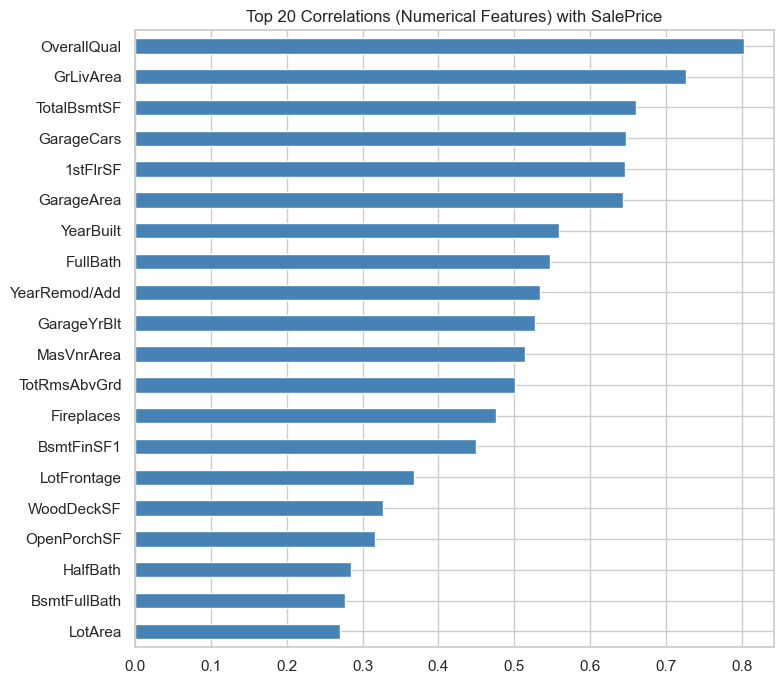

In [88]:
corr_target = df.select_dtypes(include="number").corr()[cible].drop(cible).sort_values(key=abs, ascending=False)

fig, ax = plt.subplots(figsize=(8, 7))
corr_target.head(20).sort_values().plot.barh(ax=ax, color="steelblue")
ax.set_title("Top 20 Correlations (Numerical Features) with SalePrice")
plt.tight_layout(); plt.show()

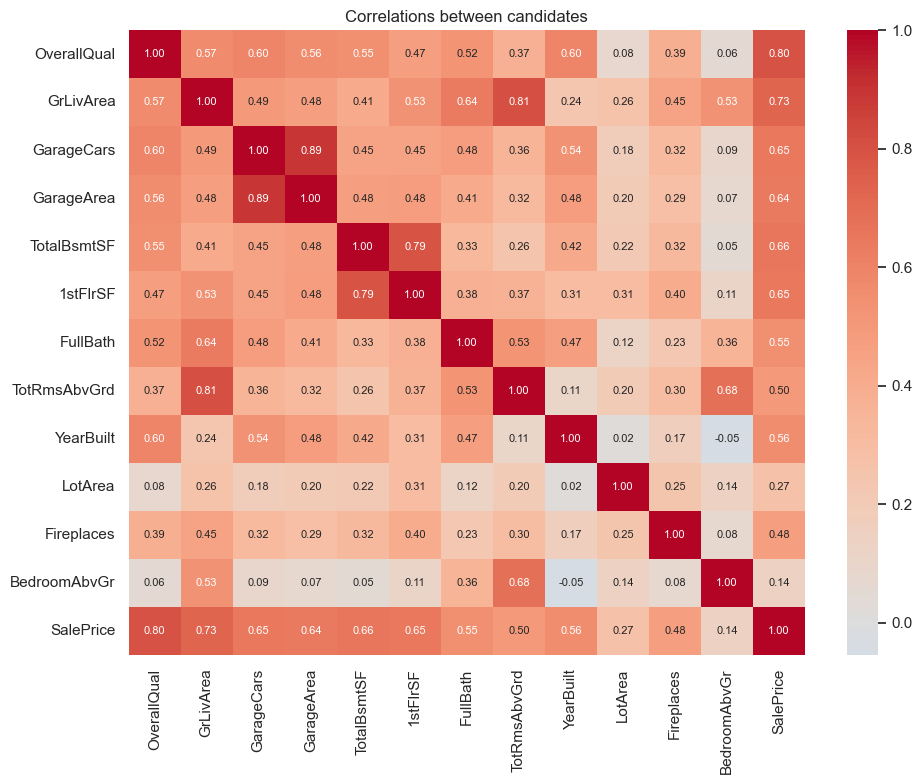

In [89]:
candidates = ["OverallQual", "GrLivArea", "GarageCars", "GarageArea", "TotalBsmtSF", "1stFlrSF",
              "FullBath", "TotRmsAbvGrd", "YearBuilt", "YearRemodAdd", "LotArea", "Fireplaces", "BedroomAbvGr"]
candidates = [c for c in candidates if c in df.columns]

plt.figure(figsize=(10, 8))
sns.heatmap(df[candidates + [cible]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 8})
plt.title("Correlations between candidates")
plt.tight_layout(); plt.show()

**Multicollinearity**: GarageCars ≈ GarageArea, 1stFlrSF ≈ TotalBsmtSF, TotRmsAbvGrd ≈ GrLivArea. We keep only one feature from each pair.

For categorical features, we examine whether the price distribution differs across categories:

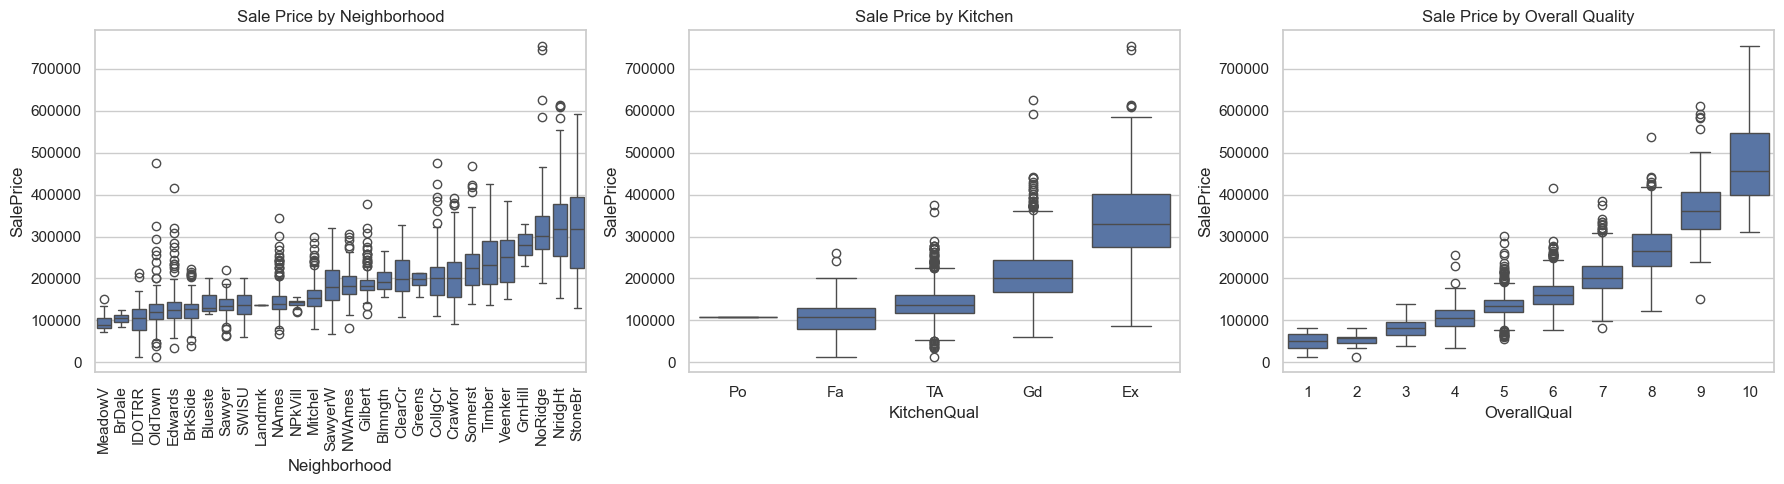

In [92]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

order = df.groupby("Neighborhood")[cible].median().sort_values(ascending=True).index

sns.boxplot(data=df, x="Neighborhood", y=cible, order=order, ax=axes[0])
axes[0].tick_params(axis="x", rotation=90); axes[0].set_title("Sale Price by Neighborhood")

qual_order = df.groupby("KitchenQual")[cible].median().sort_values(ascending=True).index
sns.boxplot(data=df, x="KitchenQual", y=cible, order=qual_order, ax=axes[1])
axes[1].set_title("Sale Price by Kitchen")

sns.boxplot(data=df, x="OverallQual", y=cible, ax=axes[2])
axes[2].set_title("Sale Price by Overall Quality")

plt.tight_layout()
plt.show()

**Selected Features** (a balance between predictive performance and simplicity, making the model suitable for use in a consumer-facing application):

| Type | Features |
|---|---|
| Numerical | `OverallQual`, `GrLivArea`, `GarageCars`, `TotalBsmtSF`, `FullBath`, `YearBuilt`, `YearRemodAdd`, `LotArea`, `Fireplaces`, `BedroomAbvGr` |
| Ordinal (quality) | `ExterQual`, `KitchenQual`, `BsmtQual` |
| Nominal | `Neighborhood`, `BldgType` |

In [94]:
df.columns = df.columns.str.replace('/', '') #YearRemodd/Add to #YearRemoddAdd

In [95]:
num_features = ["OverallQual", "GrLivArea", "GarageCars", "TotalBsmtSF", "FullBath", "YearBuilt",
                "YearRemodAdd", "LotArea", "Fireplaces", "BedroomAbvGr"]
ord_features = ["ExterQual", "KitchenQual", "BsmtQual"]
nom_features = ["Neighborhood", "BldgType"]
features = num_features + ord_features + nom_features

qual_order = ["None", "Po", "Fa", "TA", "Gd", "Ex"]   # Ascending order of quality 

X = df[features].copy()
y = df[cible].copy()

print(f"{len(features)} features selected out of {df.shape[1] - 1}")

15 features selected out of 79


### 2.3 Missing Values in the Selected Features

In [96]:
m = X.isna().sum()
print("Missing Values Among the Selected Features:")
print(m[m > 0])

Missing Values Among the Selected Features:
GarageCars      1
TotalBsmtSF     1
BsmtQual       78
dtype: int64


**Preprocessing Strategy** (implemented within a `Pipeline` to prevent data leakage — statistics are calculated using only the training set):

- **Numerical features**: imputation using the **median** (robust to outliers).
- **Categorical features**: NaN → "None" (= absence of a feature or facility, see note above).

### 2.4 Categorical Feature Encoding

- **Ordinal features** (ExterQual, KitchenQual, BsmtQual): None < Po < Fa < TA < Gd < Ex → OrdinalEncoder with an explicitly defined order (0 to 5), preserving the notion of quality from lowest to highest.
- **Nominal features** (Neighborhood, BldgType): no natural ordering → OneHotEncoder (one binary 0/1 column per category).
- **Numerical features** are standardized only for Linear Regression (standardization is unnecessary for tree-based models).

In [97]:
# First, we define a function that fills the NA values for numeric, ordinal and nominal features. It'll also transform nominal values in numerical ones. It standardizes numerical values if we need.
def make_preprocessor(scale=False):
    num_steps = [("imputer", SimpleImputer(strategy="median"))] # We use SimpleImputer to fill NA values. We use median because it isn't sensible to extreme values
    if scale: #if it's necessary, we can standardize our variables
        num_steps.append(("scaler", StandardScaler()))
    return ColumnTransformer([
        ("num", Pipeline(num_steps), num_features),
        ("ord", Pipeline([
            ("imputer", SimpleImputer(strategy="constant", fill_value="None")),
            ("encoder", OrdinalEncoder(categories=[qual_order] * len(ord_features),
                                       handle_unknown="use_encoded_value", unknown_value=-1)),
        ]), ord_features),
        ("nom", Pipeline([
            ("imputer", SimpleImputer(strategy="constant", fill_value="None")),
            ("encoder", OneHotEncoder(handle_unknown="ignore")),
        ]), nom_features),
    ])

In [98]:
# now, full Pipeline : preprocess + model, trained in log(1+prix), prediction in $.
# as mentionned earlier, to reduce the asymmetry, we use log1p(x) (which means (log(1+x))   
def make_model(estimator, scale=False):
    pipe = Pipeline([("prep", make_preprocessor(scale)), ("model", estimator)])
    return TransformedTargetRegressor(regressor=pipe, func=np.log1p, inverse_func=np.expm1)

### 2.5 Separation training / test

In [99]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print(f"Train : {X_train.shape[0]} houses \nTest : {X_test.shape[0]} houses")
print(f"Mean Sale Price  train : {y_train.mean():,.0f} $  \nMean Sale Price test : {y_test.mean():,.0f} $")

# a glimpse after preprocessing on training set 
demo = make_preprocessor(scale=False).fit(X_train)
print(f"\nAfter preprocessing : {demo.transform(X_train).shape[1]} numerical columns (against {len(features)} at the beginning)")

Train : 2336 houses 
Test : 585 houses
Mean Sale Price  train : 180,812 $  
Mean Sale Price test : 181,582 $

After preprocessing : 46 numerical columns (against 15 at the beginning)


## Step 3 — Training models

Comparison of three models :
- **Linear Regression** 
- **Random Forest**
- **Gradient Boosting**

In [43]:
models = {
    "Linear regression": make_model(LinearRegression(), scale=True),
    "Random Forest": make_model(RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)),
    "Gradient Boosting": make_model(GradientBoostingRegressor(n_estimators=300, learning_rate=0.05,
                                                              max_depth=3, random_state=RANDOM_STATE)),
}

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_scores = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    cv_scores[name] = cross_val_score(model, X_train, y_train, cv=cv, scoring="r2", n_jobs=-1)
    print(f"{name:<20} trained | R² cross-validation (5-fold) : {cv_scores[name].mean():.3f} ± {cv_scores[name].std():.3f}")

Linear regression    trained | R² cross-validation (5-fold) : 0.909 ± 0.012
Random Forest        trained | R² cross-validation (5-fold) : 0.883 ± 0.015
Gradient Boosting    trained | R² cross-validation (5-fold) : 0.906 ± 0.013


## Step 4 — Assessment

- **MAE** : Mean absolute error (in $).
- **RMSE** : root mean square error (in $).
- **R²**

In [58]:
def evaluate(model, X_, y_):
    pred = model.predict(X_)
    return {"MAE": mean_absolute_error(y_, pred),
            "RMSE": np.sqrt(mean_squared_error(y_, pred)),
            "R²": r2_score(y_, pred)}

In [59]:
rows = []
for name, model in models.items():
    tr, te = evaluate(model, X_train, y_train), evaluate(model, X_test, y_test)
    rows.append({"Model": name,
                 "MAE train": tr["MAE"], "MAE test": te["MAE"],
                 "RMSE train": tr["RMSE"], "RMSE test": te["RMSE"],
                 "R² train": tr["R²"], "R² test": te["R²"],
                 "R² CV": cv_scores[name].mean()})
results = pd.DataFrame(rows).set_index("Model")
results.style.format({"MAE train": "{:,.0f}", "MAE test": "{:,.0f}", "RMSE train": "{:,.0f}", "RMSE test": "{:,.0f}",
                      "R² train": "{:.3f}", "R² test": "{:.3f}", "R² CV": "{:.3f}"}) \
             .highlight_min(subset=["MAE test", "RMSE test"], color="lightgreen") \
             .highlight_max(subset=["R² test"], color="lightgreen")

,MAE train,MAE test,RMSE train,RMSE test,R² train,R² test,R² CV
Model,,,,,,,
Linear regression,"15,889","16,160","22,308","23,222",0.917,0.933,0.909
Random Forest,"6,314","16,360","9,800","25,249",0.984,0.921,0.883
Gradient Boosting,"12,644","15,330","17,498","22,166",0.949,0.939,0.906


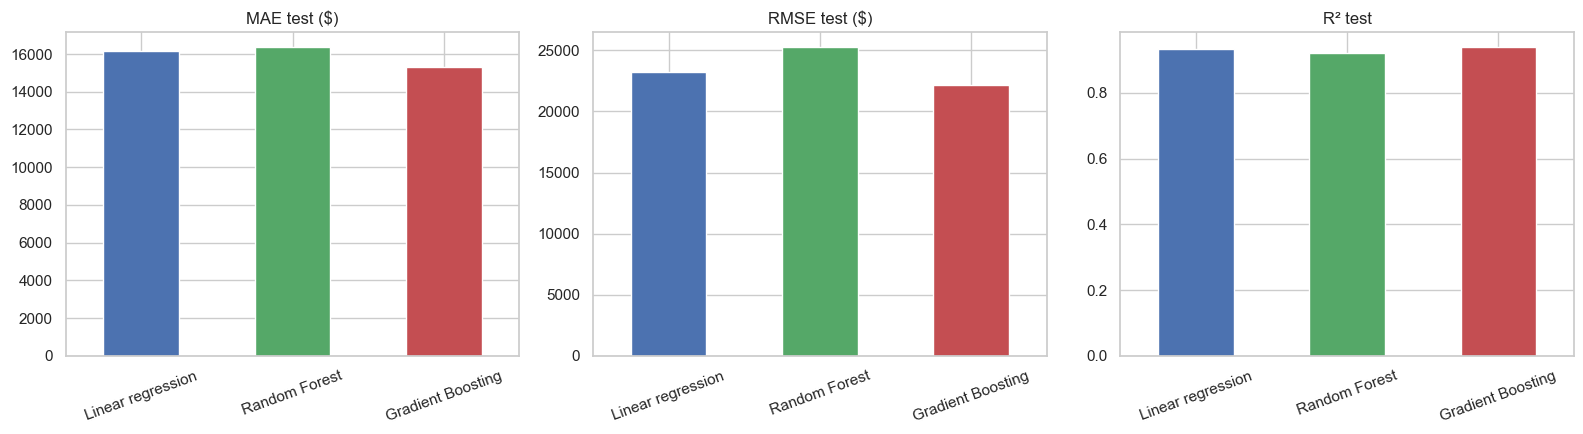

In [60]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (metric, title) in zip(axes, [("MAE test", "MAE test ($)"),
                                      ("RMSE test", "RMSE test ($)"),
                                      ("R² test", "R² test")]):
    results[metric].plot.bar(ax=ax, color=["#4C72B0", "#55A868", "#C44E52"])
    ax.set_title(title); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

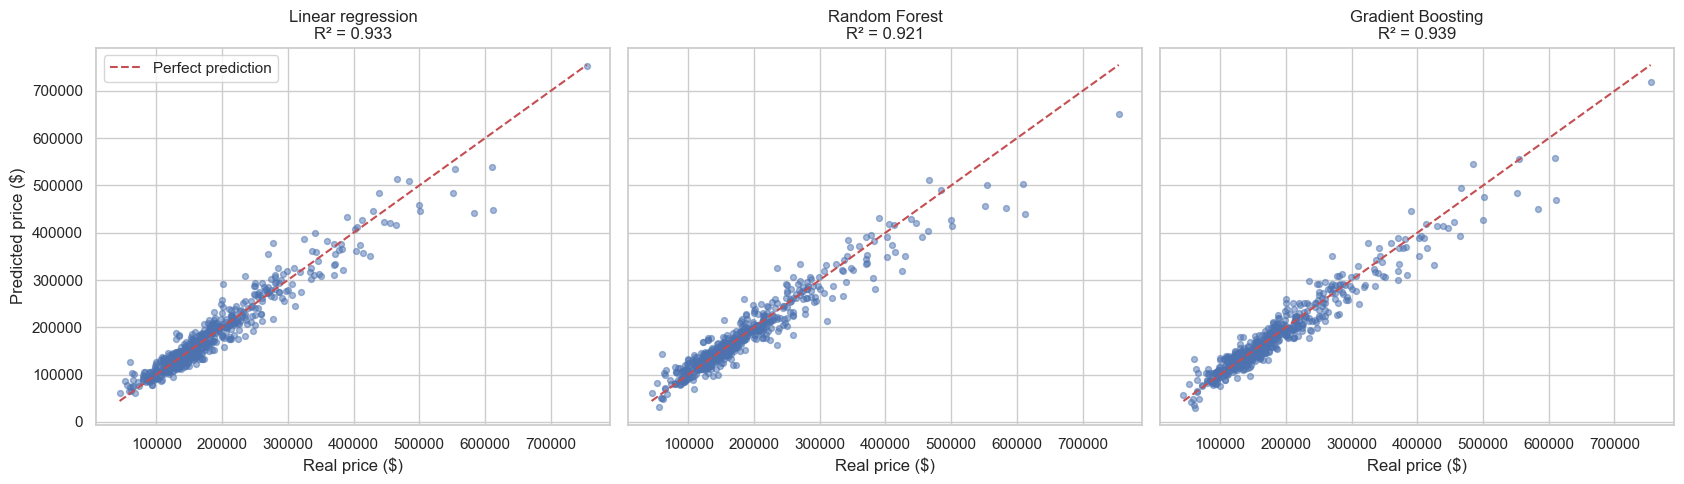

In [61]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharex=True, sharey=True)
lims = [y_test.min(), y_test.max()]

for ax, (name, model) in zip(axes, models.items()):
    ax.scatter(y_test, model.predict(X_test), alpha=0.5, s=18)
    ax.plot(lims, lims, "r--", label="Perfect prediction")
    ax.set_title(f"{name}\nR² = {results.loc[name, 'R² test']:.3f}")
    ax.set_xlabel("Real price ($)")

axes[0].set_ylabel("Predicted price ($)"); axes[0].legend()

plt.tight_layout()
plt.show()

 Best model (the lowest RMSE test) : Gradient Boosting
 MAE = 15,330 $ | RMSE = 22,166 $ | R² = 0.939


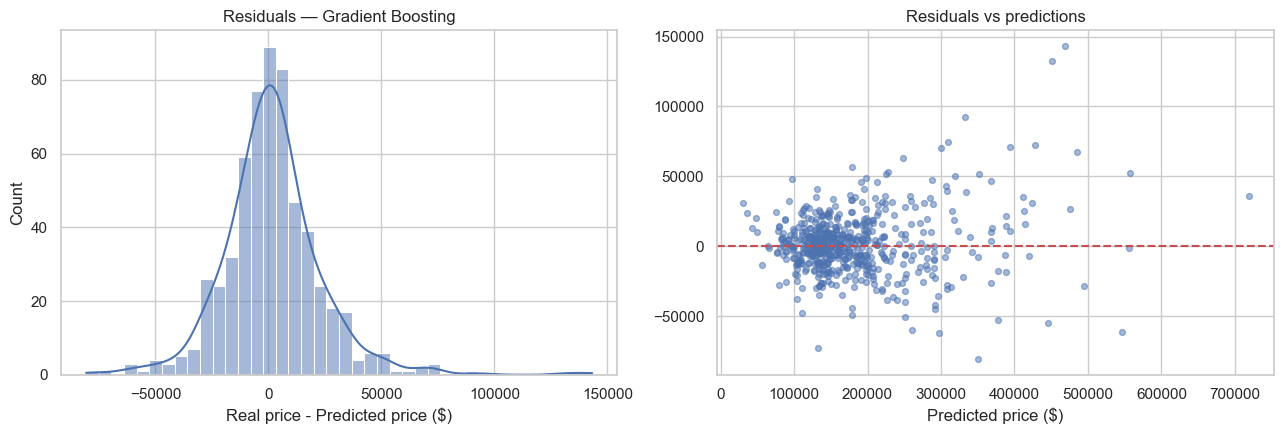

In [62]:
best_name = results["RMSE test"].idxmin()
print(f" Best model (the lowest RMSE test) : {best_name}")
print(f" MAE = {results.loc[best_name, 'MAE test']:,.0f} $ | RMSE = {results.loc[best_name, 'RMSE test']:,.0f} $ | R² = {results.loc[best_name, 'R² test']:.3f}")

best_model = models[best_name]
residuals = y_test - best_model.predict(X_test)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.histplot(residuals, bins=40, kde=True, ax=axes[0]); axes[0].set_title(f"Residuals — {best_name}")

axes[0].set_xlabel("Real price - Predicted price ($)")
axes[1].scatter(best_model.predict(X_test), residuals, alpha=0.5, s=18)
axes[1].axhline(0, color="r", ls="--"); axes[1].set_title("Residuals vs predictions")
axes[1].set_xlabel("Predicted price ($)")

plt.tight_layout()
plt.show()

**Interpretation**
- Linear regression (with a log-transformed target) provides a solid baseline, but it fails to capture nonlinear relationships and interactions (e.g., the effect of property size varying across neighborhoods).
- Tree-based ensemble models generally improve all three metrics. However, also compare the train/test gap: a large gap, often observed with Random Forest, may indicate overfitting.
- The best model is selected based on the **test RMSE**, which penalizes large prediction errors—a critical consideration for a real estate agency that wants to avoid significant mispricing.

## Step 5 — Bonus

### 5.1 Optimisation of hyperparameters with `GridSearchCV`
We optimize **Gradient Boosting**.

In [63]:
base_gb = make_model(GradientBoostingRegressor(random_state=RANDOM_STATE))

param_grid = {
    "regressor__model__n_estimators": [200, 400],
    "regressor__model__learning_rate": [0.03, 0.05, 0.1],
    "regressor__model__max_depth": [2, 3, 4],
    "regressor__model__subsample": [0.8, 1.0],
}

grid = GridSearchCV(base_gb, param_grid, cv=5, scoring="neg_root_mean_squared_error", n_jobs=-1, verbose=1)
grid.fit(X_train, y_train)

print("\nBest hyperparameters :")
for k, v in grid.best_params_.items():
    print(f"  {k.split('__')[-1]:<15} = {v}")
print(f"\nMean Cross-Validation RMSE : {-grid.best_score_:,.0f} $")

Fitting 5 folds for each of 36 candidates, totalling 180 fits

Best hyperparameters :
  learning_rate   = 0.05
  max_depth       = 3
  n_estimators    = 400
  subsample       = 0.8

Mean Cross-Validation RMSE : 22,992 $


In [64]:
tuned_gb = grid.best_estimator_
tuned_metrics = evaluate(tuned_gb, X_test, y_test)
results.loc["Gradient Boosting (optimized)"] = {
    "MAE train": evaluate(tuned_gb, X_train, y_train)["MAE"], "MAE test": tuned_metrics["MAE"],
    "RMSE train": evaluate(tuned_gb, X_train, y_train)["RMSE"], "RMSE test": tuned_metrics["RMSE"],
    "R² train": evaluate(tuned_gb, X_train, y_train)["R²"], "R² test": tuned_metrics["R²"],
    "R² CV": np.nan,
}
display(results[["MAE test", "RMSE test", "R² test"]].round(3).style.format(
    {"MAE test": "{:,.0f}", "RMSE test": "{:,.0f}", "R² test": "{:.3f}"}))

all_models = {**models, "Gradient Boosting (optimized)": tuned_gb}
final_name = results["RMSE test"].idxmin()
final_model = all_models[final_name]
print(f"\n final model : {final_name}")

,MAE test,RMSE test,R² test
Model,,,
Linear regression,"16,160","23,222",0.933
Random Forest,"16,360","25,249",0.921
Gradient Boosting,"15,330","22,166",0.939
Gradient Boosting (optimized),"14,875","21,539",0.942



 final model : Gradient Boosting (optimized)


### 5.2 Variables les plus importantes

On utilise l'**importance par permutation** sur le jeu de test : on mélange une variable à la fois et on mesure la dégradation du RMSE.
Cette méthode fonctionne avec n'importe quel modèle et travaille sur les variables d'origine (et non sur les colonnes encodées).

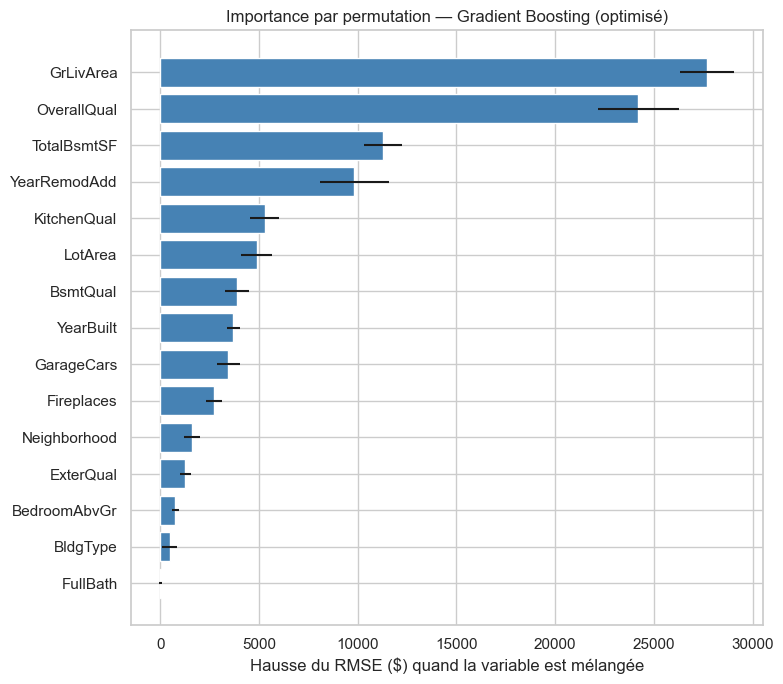

Top 5 : GrLivArea, OverallQual, TotalBsmtSF, YearRemodAdd, KitchenQual


In [41]:
perm = permutation_importance(final_model, X_test, y_test, n_repeats=15, random_state=RANDOM_STATE,
                              scoring="neg_root_mean_squared_error", n_jobs=-1)
imp = pd.DataFrame({"variable": features, "importance": perm.importances_mean, "std": perm.importances_std}) \
        .sort_values("importance", ascending=True)

fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(imp["variable"], imp["importance"], xerr=imp["std"], color="steelblue")
ax.set_xlabel("Hausse du RMSE ($) quand la variable est mélangée")
ax.set_title(f"Importance par permutation — {final_name}")
plt.tight_layout(); plt.show()
print("Top 5 :", ", ".join(imp.sort_values("importance", ascending=False)["variable"].head(5)))

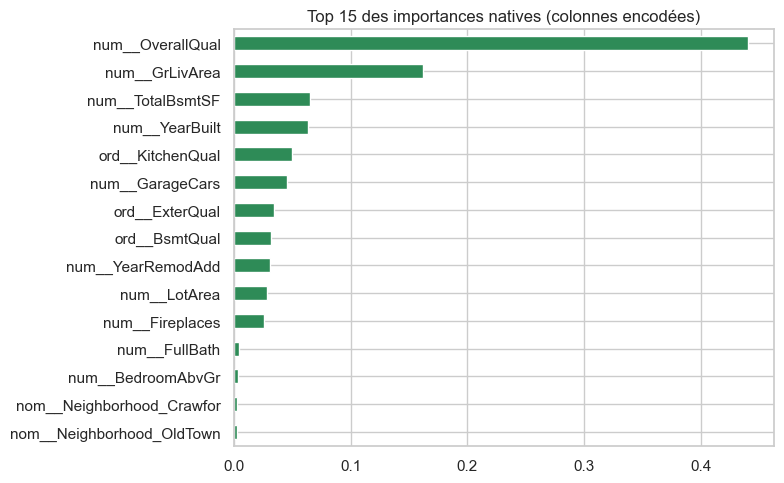

In [ ]:
# Importances natives (impureté) du modèle d'arbres, sur les colonnes encodées
inner = final_model.regressor_
if hasattr(inner.named_steps["model"], "feature_importances_"):
    names = inner.named_steps["prep"].get_feature_names_out()
    native = pd.Series(inner.named_steps["model"].feature_importances_, index=names).sort_values(ascending=False).head(15)
    fig, ax = plt.subplots(figsize=(8, 5))
    native.sort_values().plot.barh(ax=ax, color="seagreen")
    ax.set_title("Top 15 des importances natives (colonnes encodées)")
    plt.tight_layout(); plt.show()

**Lecture** : la qualité globale (`OverallQual`) et la surface habitable (`GrLivArea`) dominent, suivies du sous-sol, du quartier, de l'année de construction et du garage —
ce qui correspond à l'intuition métier d'un agent immobilier.

### 5.3 Sauvegarde du modèle avec `joblib`

In [ ]:
os.makedirs("models", exist_ok=True)
final_metrics = evaluate(final_model, X_test, y_test)

meta = {
    "model_name": final_name,
    "features": FEATURES,
    "num": {c: (float(X[c].min()), float(X[c].max()), float(X[c].median())) for c in NUM_FEATURES},
    "ord": ORD_FEATURES,
    "ord_levels": QUAL_ORDER,
    "nom": {c: sorted(X[c].dropna().unique().tolist()) for c in NOM_FEATURES},
    "mae": final_metrics["MAE"], "rmse": final_metrics["RMSE"], "r2": final_metrics["R²"],
}
joblib.dump(final_model, "models/ames_model.joblib")
joblib.dump(meta, "models/ames_meta.joblib")
print("💾 Modèle sauvegardé : models/ames_model.joblib")
print("💾 Métadonnées       : models/ames_meta.joblib")

# Vérification : rechargement + prédictions identiques
reloaded = joblib.load("models/ames_model.joblib")
assert np.allclose(reloaded.predict(X_test), final_model.predict(X_test))
print("✅ Rechargement vérifié")

💾 Modèle sauvegardé : models/ames_model.joblib
💾 Métadonnées       : models/ames_meta.joblib
✅ Rechargement vérifié


In [ ]:
# Exemple d'utilisation du modèle sauvegardé
exemple = pd.DataFrame([{
    "OverallQual": 7, "GrLivArea": 1800, "GarageCars": 2, "TotalBsmtSF": 900, "FullBath": 2,
    "YearBuilt": 2000, "YearRemodAdd": 2005, "LotArea": 9000, "Fireplaces": 1, "BedroomAbvGr": 3,
    "ExterQual": "Gd", "KitchenQual": "Gd", "BsmtQual": "Gd",
    "Neighborhood": X["Neighborhood"].mode()[0], "BldgType": "1Fam",
}])[FEATURES]
print(f"Prix estimé de la maison exemple : {reloaded.predict(exemple)[0]:,.0f} $")

Prix estimé de la maison exemple : 212,008 $


### 5.4 Application Streamlit

Le code de l'application est écrit dans `app.py` (cellule ci-dessous). Elle charge `models/ames_model.joblib`, affiche un formulaire pour saisir les caractéristiques de la maison et renvoie le prix estimé avec une fourchette (± MAE).

Lancement depuis un terminal, dans le dossier du projet :
```bash
pip install streamlit
streamlit run app.py
```

In [ ]:
%%writefile app.py
import joblib
import pandas as pd
import streamlit as st

st.set_page_config(page_title="Estimation immobilière - Ames", page_icon="🏠")

MODEL_PATH = "models/ames_model.joblib"
META_PATH = "models/ames_meta.joblib"

QUAL_LABELS = {
    "Ex": "Excellent", "Gd": "Bon", "TA": "Moyen / typique",
    "Fa": "Passable", "Po": "Mauvais", "None": "Aucun / absent",
}


@st.cache_resource
def load_artifacts():
    return joblib.load(MODEL_PATH), joblib.load(META_PATH)


try:
    model, meta = load_artifacts()
except FileNotFoundError:
    st.error("Modèle introuvable. Exécutez d'abord le notebook pour générer le dossier `models/`.")
    st.stop()

st.title("🏠 Estimateur de prix de maison")
st.caption(
    f"Modèle : **{meta['model_name']}** · MAE test ≈ {meta['mae']:,.0f} $ · "
    f"R² test = {meta['r2']:.3f} · Données : Ames Housing (Iowa, USA)"
)

st.header("Caractéristiques de la maison")
col1, col2 = st.columns(2)
inputs = {}

LABELS = {
    "OverallQual": "Qualité globale (1-10)",
    "GrLivArea": "Surface habitable hors sous-sol (sq ft)",
    "GarageCars": "Places de garage",
    "TotalBsmtSF": "Surface du sous-sol (sq ft)",
    "FullBath": "Salles de bain complètes",
    "YearBuilt": "Année de construction",
    "YearRemodAdd": "Année de rénovation",
    "LotArea": "Surface du terrain (sq ft)",
    "Fireplaces": "Cheminées",
    "BedroomAbvGr": "Chambres (hors sous-sol)",
}

for i, (name, (vmin, vmax, vmed)) in enumerate(meta["num"].items()):
    target = col1 if i % 2 == 0 else col2
    with target:
        inputs[name] = st.number_input(
            LABELS.get(name, name), min_value=int(vmin), max_value=int(vmax * 1.2),
            value=int(vmed), step=1,
        )

st.subheader("Qualité et type de bien")
col3, col4 = st.columns(2)
for i, name in enumerate(meta["ord"]):
    target = col3 if i % 2 == 0 else col4
    with target:
        inputs[name] = st.selectbox(
            name, meta["ord_levels"], index=meta["ord_levels"].index("TA"),
            format_func=lambda x: f"{x} - {QUAL_LABELS.get(x, x)}",
        )
for i, (name, options) in enumerate(meta["nom"].items()):
    target = col3 if i % 2 == 0 else col4
    with target:
        inputs[name] = st.selectbox(name, options)

if st.button("Estimer le prix", type="primary"):
    X_new = pd.DataFrame([inputs])[meta["features"]]
    price = float(model.predict(X_new)[0])
    st.success(f"Prix estimé : **{price:,.0f} $**")
    st.write(
        f"Fourchette indicative (± MAE du modèle) : "
        f"{max(price - meta['mae'], 0):,.0f} $ - {price + meta['mae']:,.0f} $"
    )
    st.caption("Estimation statistique, à utiliser comme aide à la décision et non comme expertise officielle.")

Writing app.py


## Conclusion

| Étape | Résultat |
|---|---|
| Exploration | Prix asymétrique (→ log), NaN souvent = « équipement absent », 5 aberrations retirées |
| Préparation | 15 variables retenues, pipeline sans fuite de données (imputation + encodage ordinal / one-hot) |
| Modèles | Régression linéaire, Random Forest, Gradient Boosting comparés en validation croisée et sur test |
| Évaluation | Meilleur modèle choisi selon RMSE test ; MAE, RMSE et R² reportés en dollars |
| Bonus | `GridSearchCV`, importance par permutation, export `joblib`, application Streamlit |

**Pistes d'amélioration** : ajout de variables (surface totale, âge du bien, salles de bain totales), `RandomizedSearchCV` plus large, modèles XGBoost / LightGBM, intervalles de prédiction par quantiles.